In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

# import sklearn.decomposition as skd
# from factor_analyzer import FactorAnalyzer


# Obtaining Prices for Analysis

In [19]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  5 of 5 completed


In [20]:
data.head()

Ticker,AAPL,AIR.PA,ASML.AS,MC.PA,SC0D.DE
Date,,,,,
2010-01-04,6.470741,11.523581,27.279844,59.936459,47.728802
2010-01-05,6.481928,11.486515,27.330452,59.654686,47.642601
2010-01-06,6.378825,11.589478,27.622812,60.233463,47.599602
2010-01-07,6.367032,11.704795,27.116796,60.918907,47.562500
2010-01-08,6.409363,11.820114,26.205965,61.741394,47.728401


In [21]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50'})
# Getting Daily Log Returns
returns = data.apply(np.log).diff(1)
# Filling non-trading days with zero returns
returns = returns.fillna(0)

In [22]:
returns

Ticker,AAPL,AIRBUS,ASML,LVMH,EURO50
Date,,,,,
2010-01-04,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-05,0.001727,-0.003222,0.001853,-0.004712,-0.001808
2010-01-06,-0.016034,0.008924,0.010640,0.009655,-0.000903
2010-01-07,-0.001850,0.009901,-0.018489,0.011316,-0.000780
2010-01-08,0.006626,0.009804,-0.034166,0.013411,0.003482
...,...,...,...,...,...
2023-12-22,-0.005563,0.006620,0.001464,-0.007697,-0.001098
2023-12-26,-0.002845,0.000000,0.000000,0.000000,0.000000
2023-12-27,0.000518,0.000000,0.000000,0.000000,0.000000


## Analysis of Returns

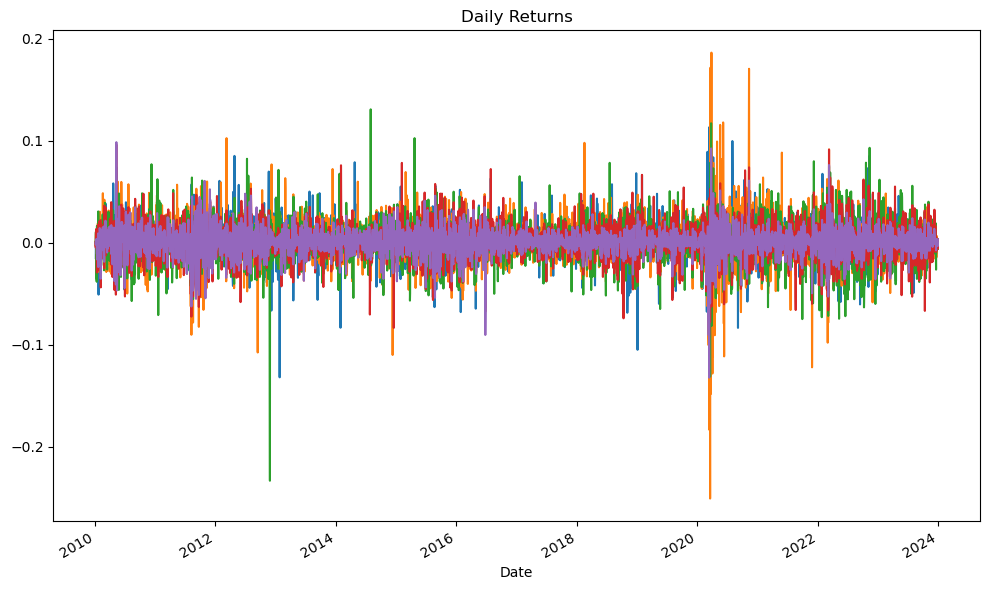

In [23]:
returns.plot(legend=0, figsize=(10,6), title='Daily Returns')
plt.tight_layout()

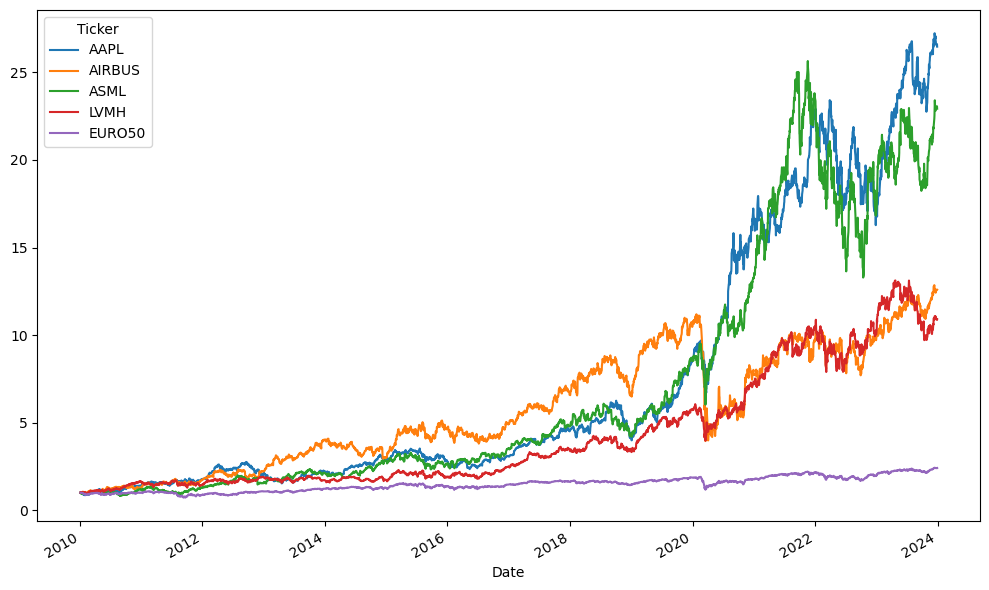

In [24]:
returns.cumsum().apply(np.exp).plot(legend=1, figsize=(10,6))
plt.tight_layout()

## Analysis of Correlation

As can be seen from the plot our portfolios are correlated and some of the assets have severe correlations. To expand on these correlations we should use copula to analyze behavior of returns better.

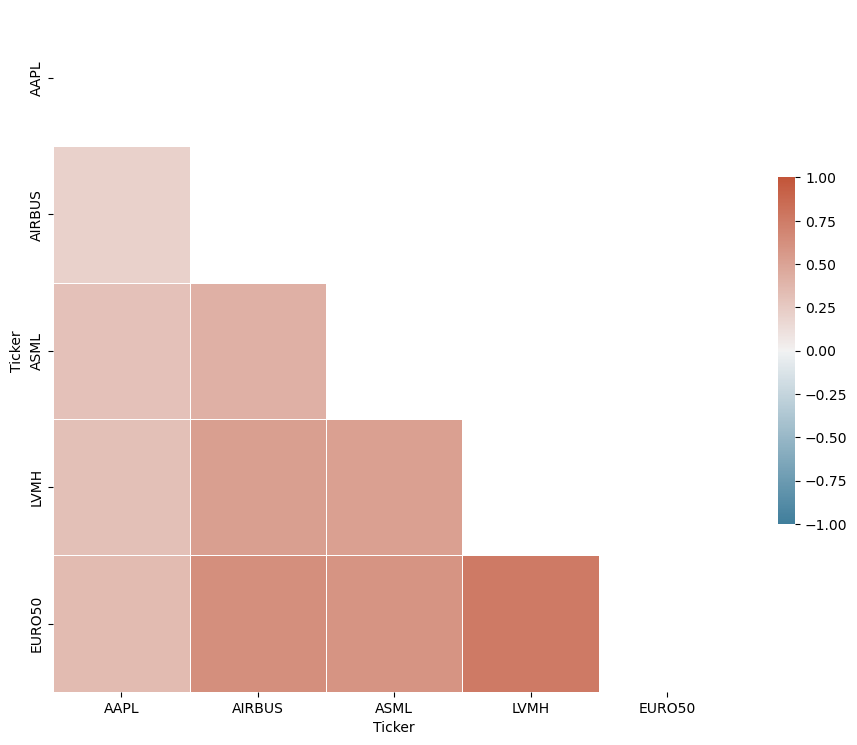

In [25]:
# calculate the correlation matrix to measure the linear relationships between the variables:
corr_matrix = returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # Create a mask for the upper triangle of the correlation matrix.

# Visualizing:
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(230, 20, as_cmap=True)     # Setting Colors
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

# Copulas

In [26]:
from copulas.bivariate import Gumbel, Clayton, Frank
from copulas.bivariate import Bivariate 
from scipy.stats import rankdata

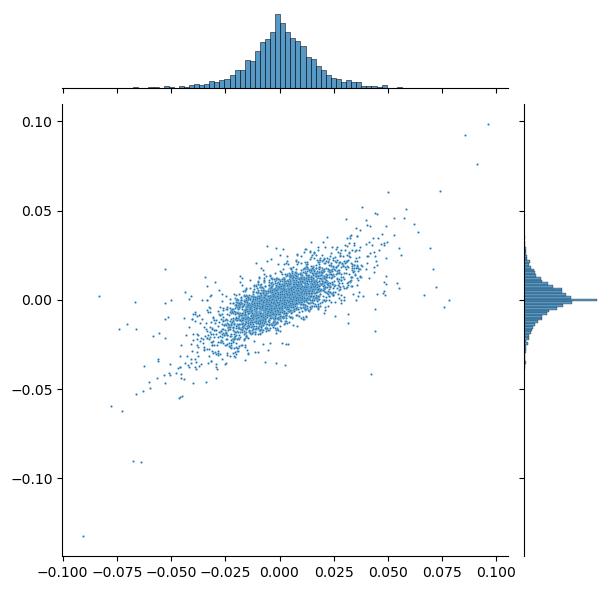

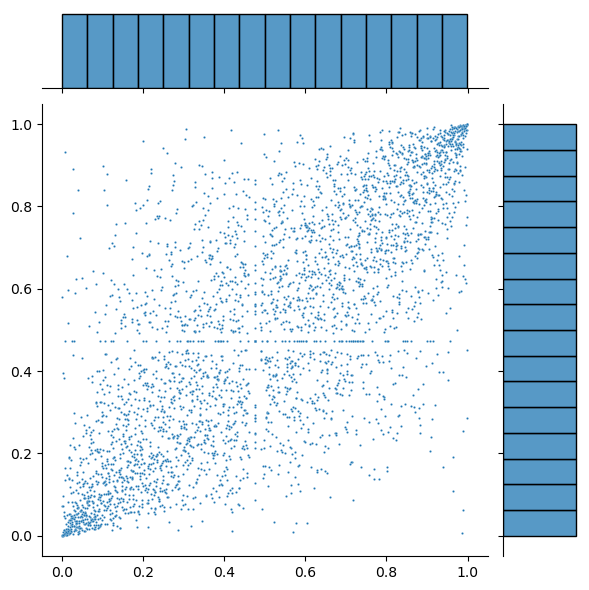

In [27]:
# Function to transform data to uniform [0, 1] using empirical CDF
def to_uniform(data):
    return (rankdata(data) - 0.5) / len(data)

# Choosing pair of data
copula_data = returns[['LVMH', 'EURO50']].to_numpy()        # We choose them because they have the highest correlation
# Transform data to uniform
uniform_data = np.column_stack((to_uniform(copula_data[:, 0]), to_uniform(copula_data[:, 1])))

sns.jointplot(x=copula_data[:, 0], y=copula_data[:, 1], kind='scatter', s=2.5)      # Joint plot of returns for our assets
sns.jointplot(x=uniform_data[:, 0], y=uniform_data[:, 1], kind='scatter', s=2.5)    # Joint plot of returns for our assets converted to uniform

In [28]:
# Finding the Optimal Copula according to the Algorithm:
# https://github.com/sdv-dev/Copulas/blob/main/copulas/bivariate/base.py
bivariate_copula = Bivariate()
best_fit_copula = bivariate_copula.select_copula(uniform_data)
print("The most suitable copula is: ", best_fit_copula.copula_type, ", tau= ", best_fit_copula.tau, " theta= ", best_fit_copula.theta)

The most suitable copula is:  CopulaTypes.GUMBEL , tau=  0.5495358209897767  theta=  2.2199323422280486


## Bivariate - Archimedean

### Clayton

In [29]:
# Fit a Gumbel copula
clayton_copula = Clayton()
clayton_copula.fit(uniform_data)

# Display the parameter, in case of Gumbel it's mainly the 'theta'
print(f"Fitted Theta: {clayton_copula.theta}")
print(f"Fitted Tau: {clayton_copula.tau}")
print(f"Log Prob per Point: {clayton_copula.log_probability_density(uniform_data)}")

Fitted Theta: 2.4398646844560976
Fitted Tau: 0.5495358209897767
Log Prob per Point: [ 0.51494929  0.67995166 -0.18262242 ...  0.51494929  0.81311168
  0.43961546]


### Frank

In [30]:
# Fit a Gumbel copula
frank_copula = Frank()
frank_copula.fit(uniform_data)

# Display the parameter, in case of Gumbel it's mainly the 'theta'
print(f"Fitted Theta: {frank_copula.theta}")
print(f"Fitted Tau: {frank_copula.tau}")
print(f"Log Prob per Point: {frank_copula.log_probability_density(uniform_data)}")

Fitted Theta: 6.717747338059889
Fitted Tau: 0.5495358209897767
Log Prob per Point: [ 0.58907594  0.6058379  -0.48596741 ...  0.58907594  0.65718018
  0.58761142]


### Gumbel

In [31]:
# Fit a Gumbel copula
gumbel_copula = Gumbel()
gumbel_copula.fit(uniform_data)

# Display the parameter, in case of Gumbel it's mainly the 'theta'
print(f"Fitted Theta: {gumbel_copula.theta}")
print(f"Fitted Tau: {gumbel_copula.tau}")
print(f"Log Prob per Point: {gumbel_copula.log_probability_density(uniform_data)}")

Fitted Theta: 2.2199323422280486
Fitted Tau: 0.5495358209897767
Log Prob per Point: [ 0.49763041  0.5051698  -0.33582899 ...  0.49763041  0.54868296
  0.56784192]


In [32]:
# Generate synthetic data
synthetic_data = gumbel_copula.sample(25_000)
synthetic_data = pd.DataFrame(list(map(np.ravel, synthetic_data)))
synthetic_data.columns = ['X', 'Y']

# Example of using synthetic data (plotting or further statistical analysis)
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='kde', s=1.0)
sns.jointplot(x=synthetic_data['X'], y=synthetic_data['Y'], kind='scatter', s=1.0)

plt.show()


In [ ]:
# TODO: Add Gaussian and t-Student Copulas, they are in the multivariate base class

## Multivariate

# Factor Analysis

## Extending portfolio

## PCA

## Factor Analysis